# Experiment 23: Full fine-tuning learning curve and parity

Five training-set sizes, validation-selected checkpoints, and matched validation/test evaluation.

Analysis date: 29 October 2026.

In [ ]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path('/Users/louismcauliffe/code/research/NequIP_experiments')
DATA = ROOT / 'experiments/21-23-LearningCurve-data'
FIG = ROOT / 'experiments/21-23-LearningCurve-figures'
metrics = pd.read_csv(DATA / 'metrics.csv')
manifest = json.loads((DATA / 'manifest.json').read_text())
assert metrics.export_matches_checkpoint.all()
valid = metrics.query("split == 'valid'")
np.testing.assert_allclose(valid.loss, valid.saved_valid_loss, rtol=1e-3, atol=1e-7)
for split in ('valid', 'test'):
    path = ROOT / f'data/nmr_iso/{split}.xyz'
    assert hashlib.sha256(path.read_bytes()).hexdigest() == manifest['input_sha256'][str(path)]
print('26 audited checkpoints: 25 primary models and one separate ELoRA pilot.')


In [ ]:
results = metrics.query('experiment == 23 and primary and split == "test"').sort_values(['n', 'experiment'])
display(results[['experiment', 'n', 'Si_rmse', 'O_rmse', 'loss', 'best_epoch', 'final_epoch', 'status', 'trainable_parameters']].reset_index(drop=True))

experiment,n,Si_rmse,O_rmse,loss,best_epoch,final_epoch,status,trainable_parameters
23,10,2.1814,4.5964,0.059458,917,1217,Early stopping,738052
23,50,1.2615,2.9864,0.022399,471,771,Early stopping,738052
23,100,1.071,2.4751,0.015735,633,933,Early stopping,738052
23,200,0.86341,2.1118,0.010875,580,880,Early stopping,738052
23,800,0.59332,1.4687,0.0052048,459,759,Early stopping,738052


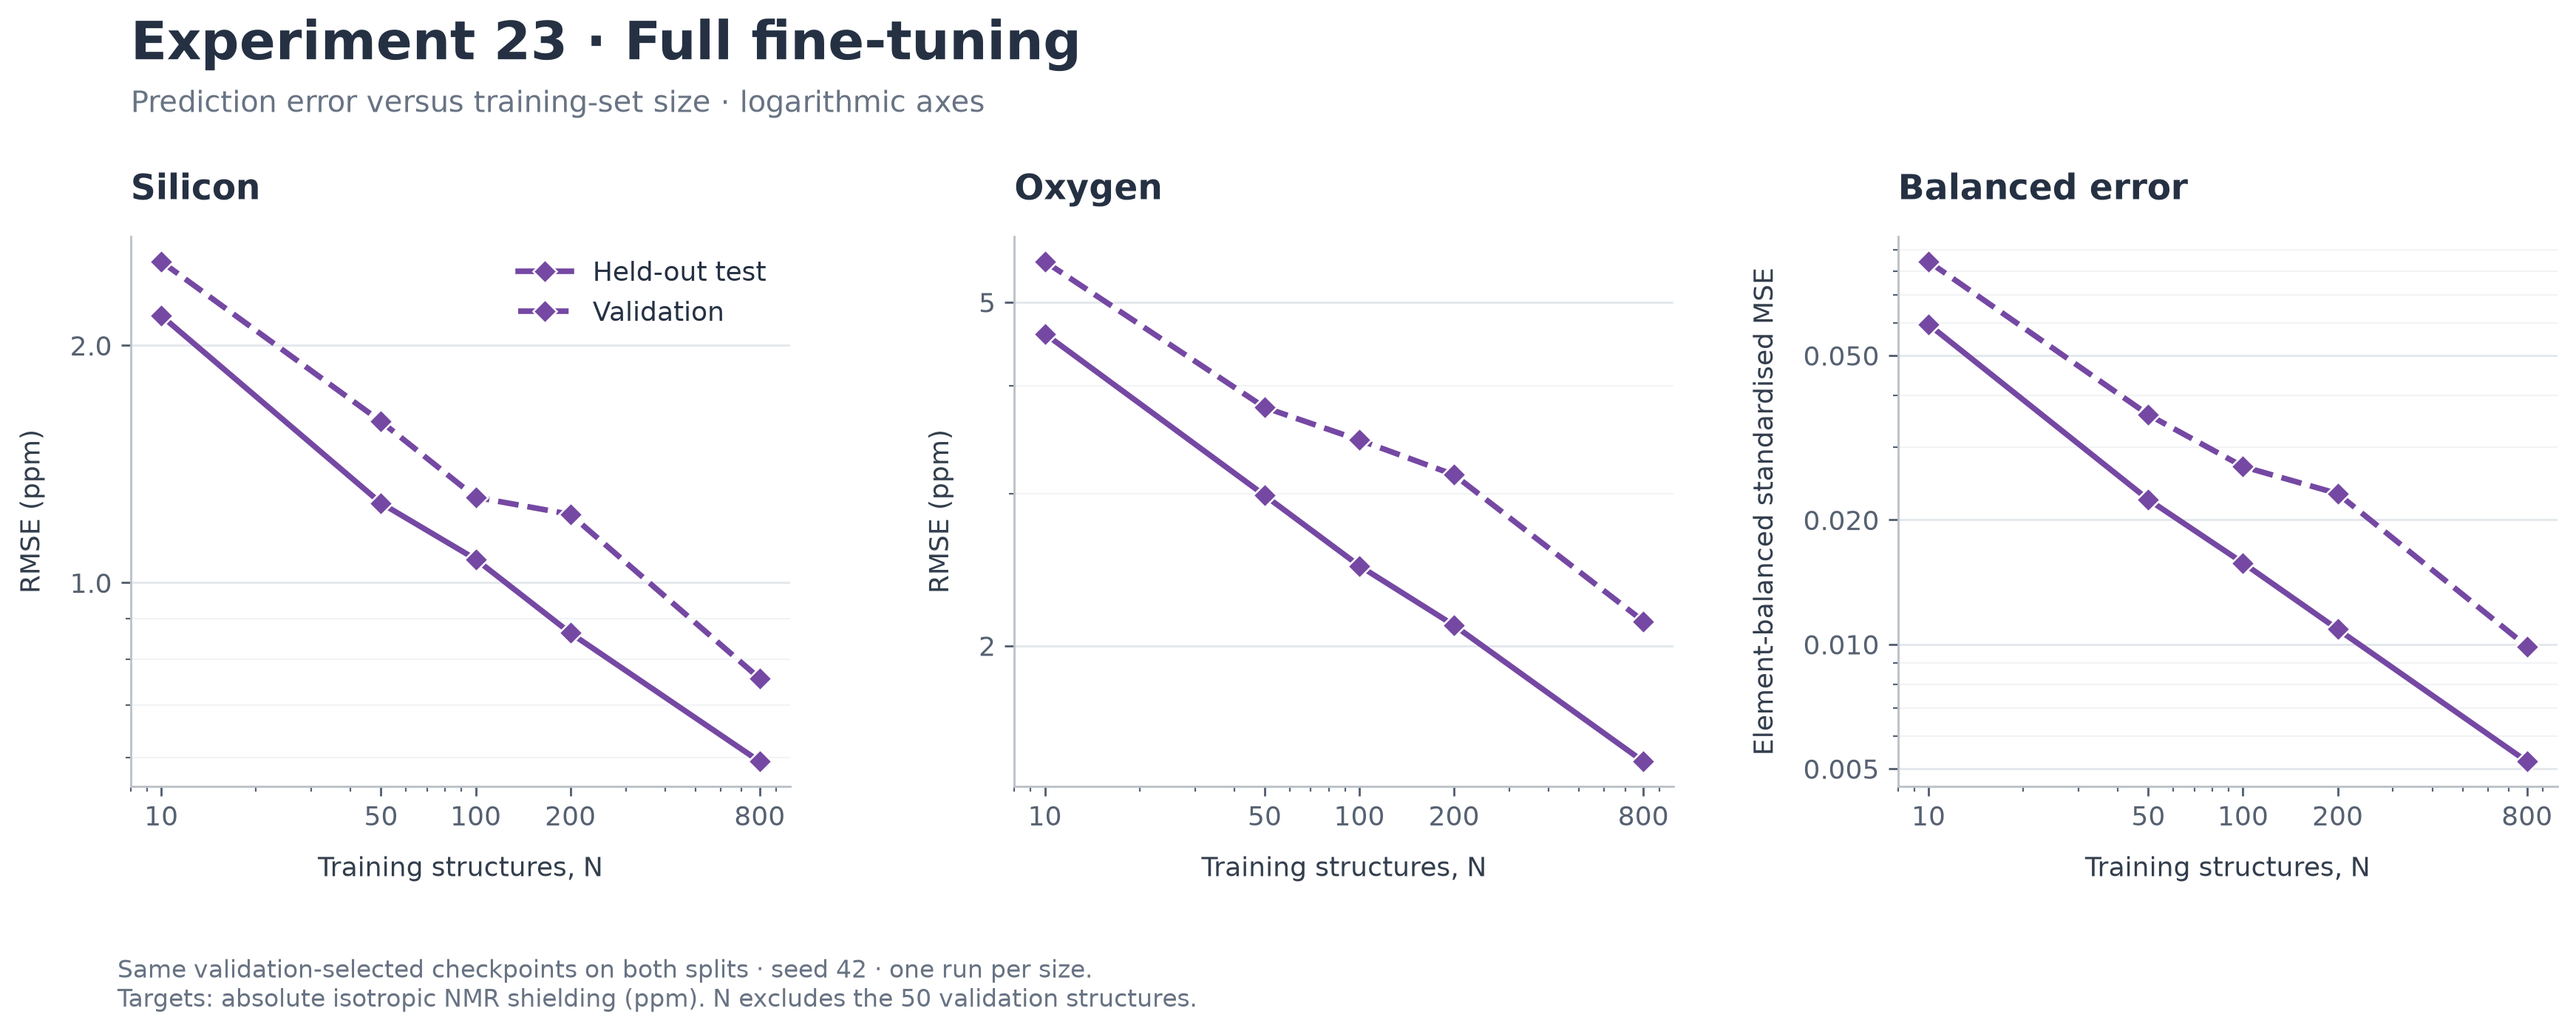

In [ ]:
display(Image(filename=str(FIG / '23-learning-curve-log-log.png')))

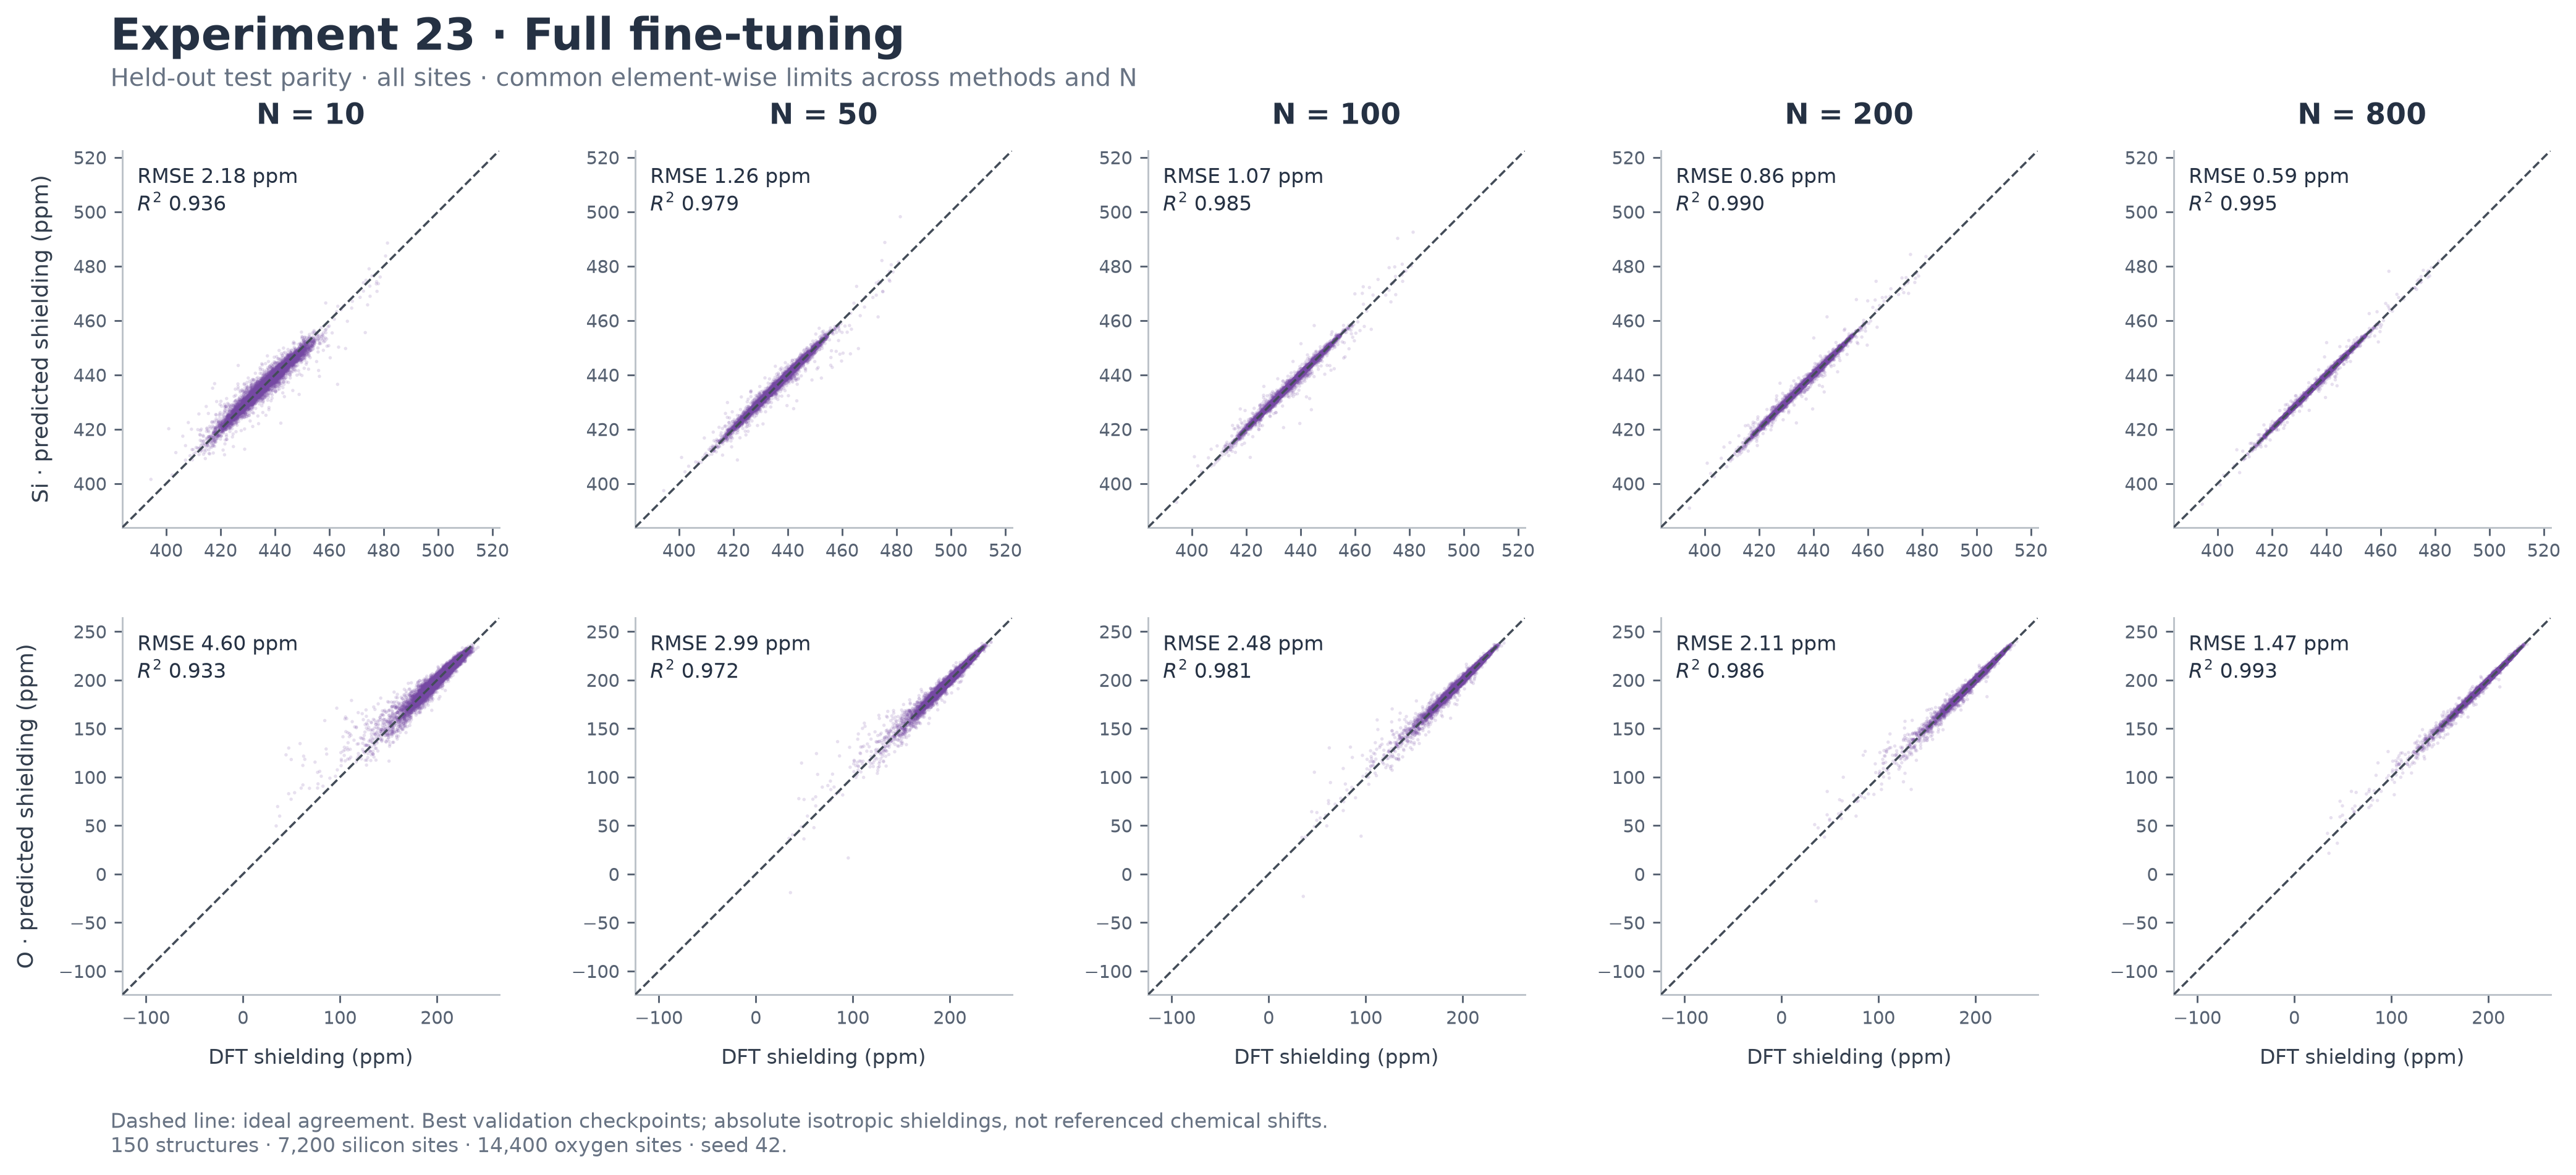

In [ ]:
display(Image(filename=str(FIG / '23-test-parity.png')))

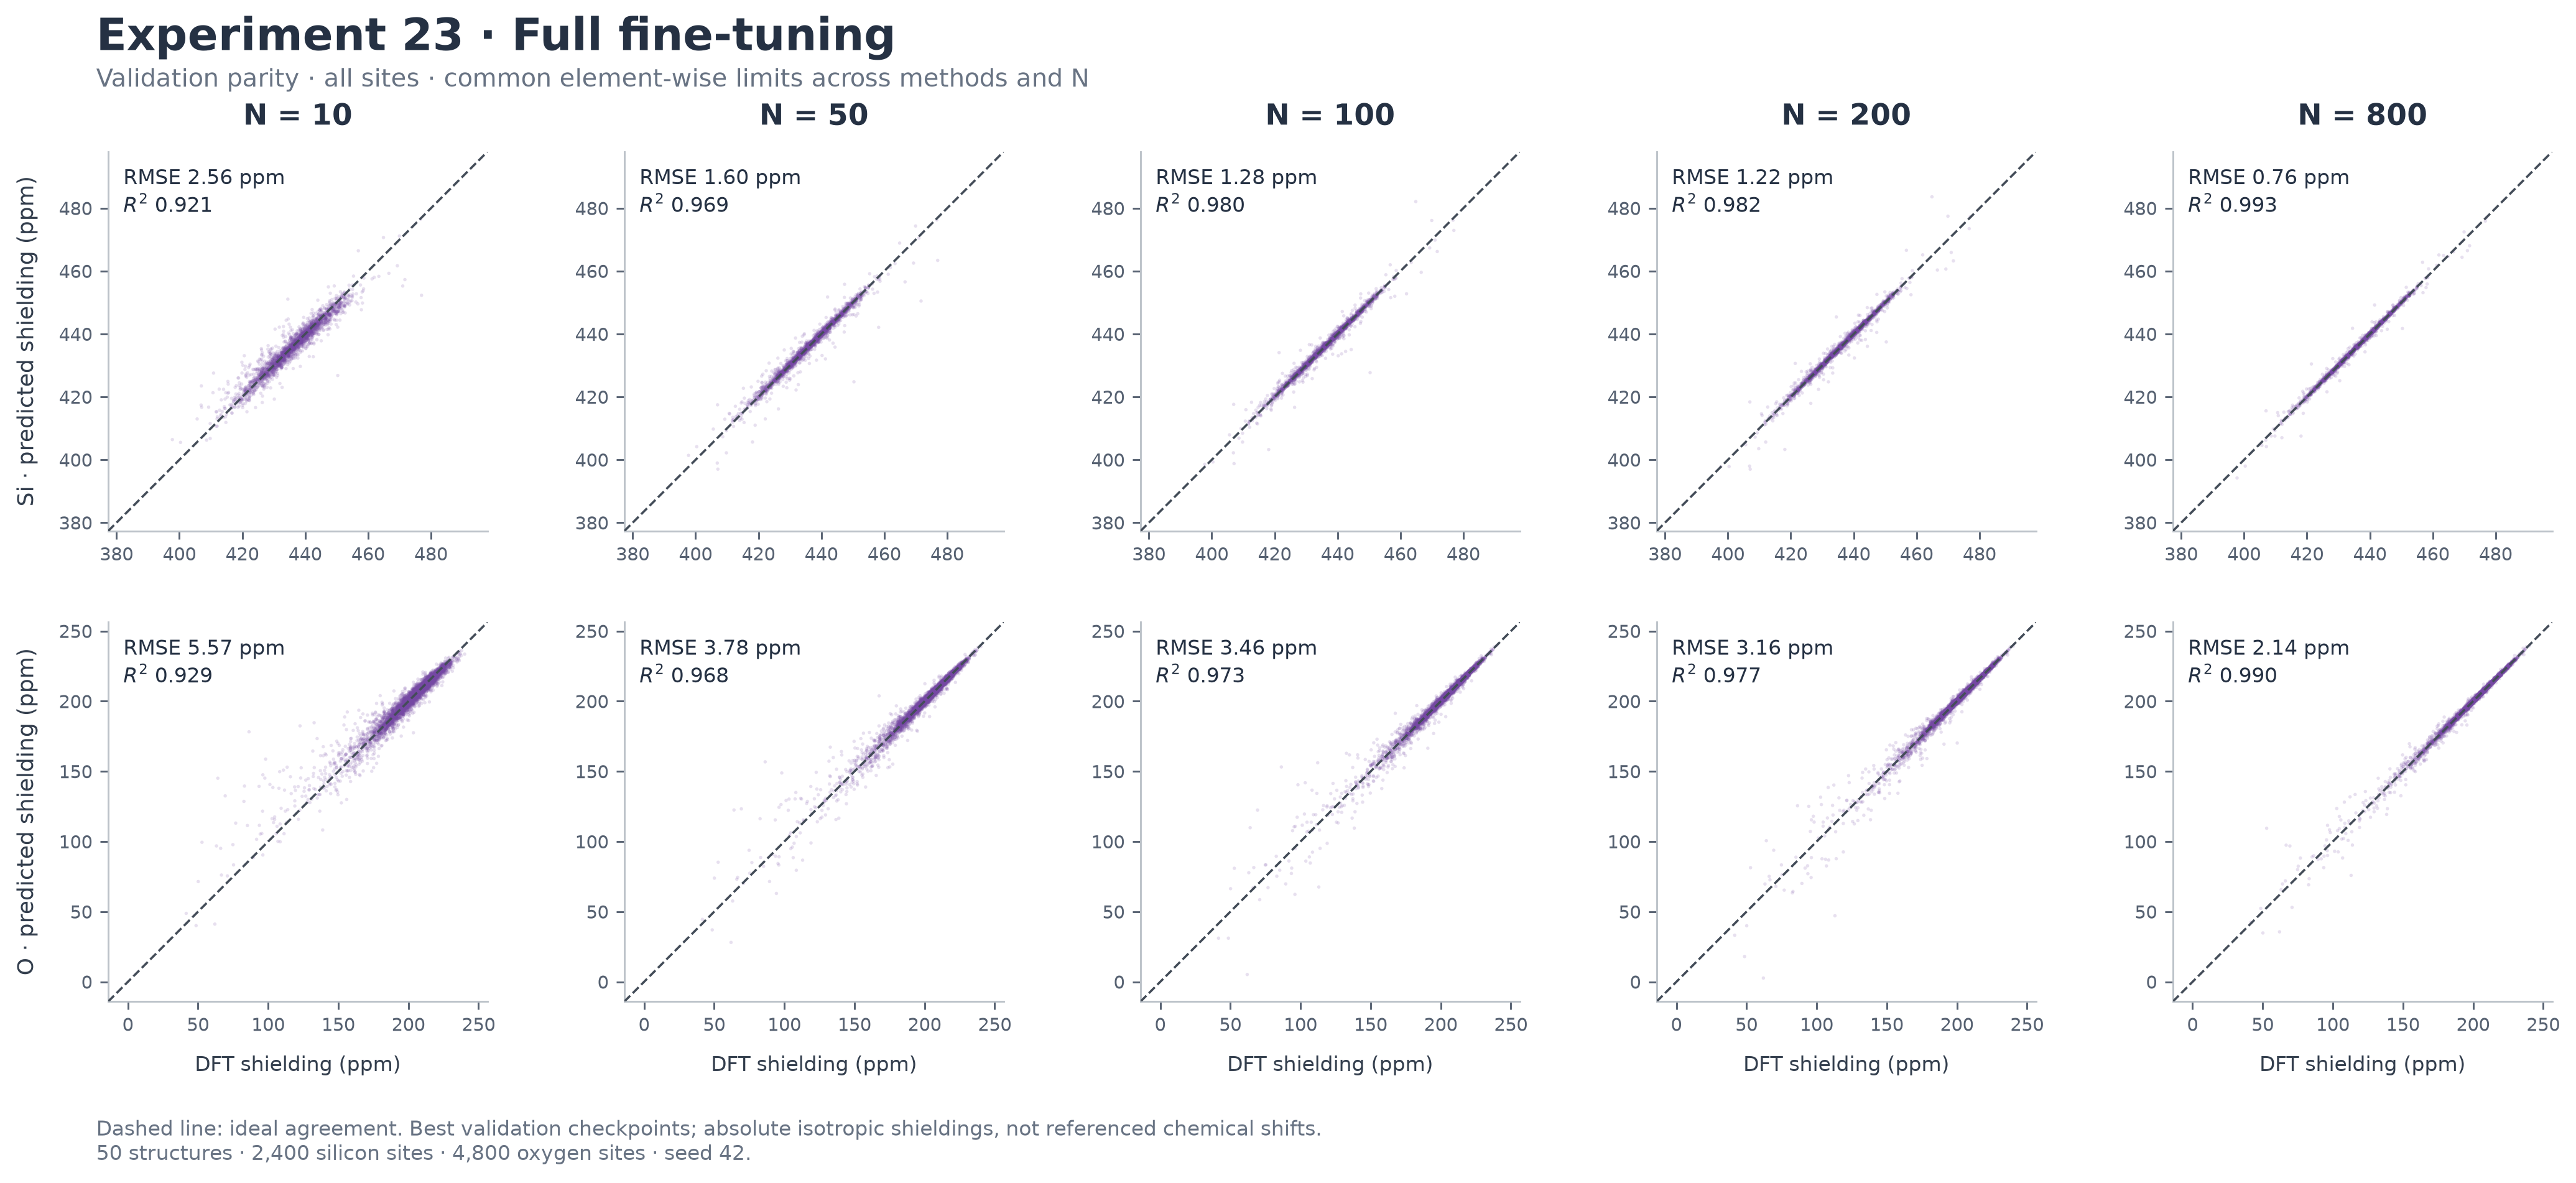

In [ ]:
display(Image(filename=str(FIG / '23-valid-parity.png')))